# Dataset Description
## Colombian Map Draw with dots per 10k inhabitants by municipality

**Population**: [DANE](https://www.dane.gov.co/index.php/estadisticas-por-tema/demografia-y-poblacion/proyecciones-de-poblacion)

**Shapefile**: [DANE](https://geoportal.dane.gov.co/servicios/descarga-y-metadatos/datos-geoestadisticos/?cod=111)

This time, due to the size of each file they were keep out of the repo, download them directly by yourselves. For the shapefile you need the file called "Versión MGN2025-Nivel Municipio"
# Code
## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import geopandas
import numpy as np
import unicodedata

## Load data

In [2]:
pop = pd.read_csv("./data/municipal.csv", usecols=["DP", "Municipio", "AÑO", "Total"])
gdf = geopandas.read_file("./data/MGN_ADM_MPIO_GRAFICO.shp")

## Clean Data

In [3]:
# The population file has no municipality code, so join on department code + normalized name
renames = {
    "SANTAFE DE ANTIOQUIA": "SANTA FE DE ANTIOQUIA",
    "SAN VICENTE": "SAN VICENTE FERRER",
    "MOMPOS": "SANTA CRUZ DE MOMPOX",
    "SAN ANDRES SOTAVENTO": "SAN ANDRES DE SOTAVENTO",
    "CHIBOLO": "CHIVOLO",
    "TOLU VIEJO": "SAN JOSE DE TOLUVIEJO",
    "MARIQUITA": "SAN SEBASTIAN DE MARIQUITA",
    "CALI": "SANTIAGO DE CALI",
}


def normalize(name):
    name = unicodedata.normalize("NFKD", name).encode("ascii", "ignore").decode()
    name = name.upper().replace("(ANM)", "").strip()
    return renames.get(name, name)


pop = pop[pop["AÑO"].eq(2026)].copy()
pop["key"] = pop["DP"].astype(str).str.zfill(2) + pop["Municipio"].map(normalize)
gdf["key"] = gdf["dpto_ccdgo"] + gdf["mpio_cnmbr"].map(normalize)

gdf = gdf.merge(pop[["key", "Total"]], on="key", how="left")
# Mapiripana (Guainía) has 0 people and no polygon, any other gap would be a join error
assert gdf["Total"].notna().all(), gdf.loc[gdf["Total"].isna(), "mpio_cnmbr"].tolist()

# Stochastic rounding keeps the total unbiased, small municipalities still get a dot sometimes
rng = np.random.default_rng(42)
people_per_dot = 10_000
dots = gdf["Total"] / people_per_dot
gdf["n_dots"] = (np.floor(dots) + (rng.random(len(gdf)) < dots % 1)).astype(int)

points = gdf.geometry.sample_points(gdf["n_dots"].to_numpy(), rng=rng).explode(index_parts=True)
# Department of each dot, through the municipality it was sampled from
points = geopandas.GeoDataFrame(
    {"department": gdf["dpto_cnmbr"].loc[points.index.get_level_values(0)].to_numpy()},
    geometry=points.to_numpy(),
)
top_departments = gdf.groupby("dpto_cnmbr")["Total"].sum().nlargest(4).index

## Plot

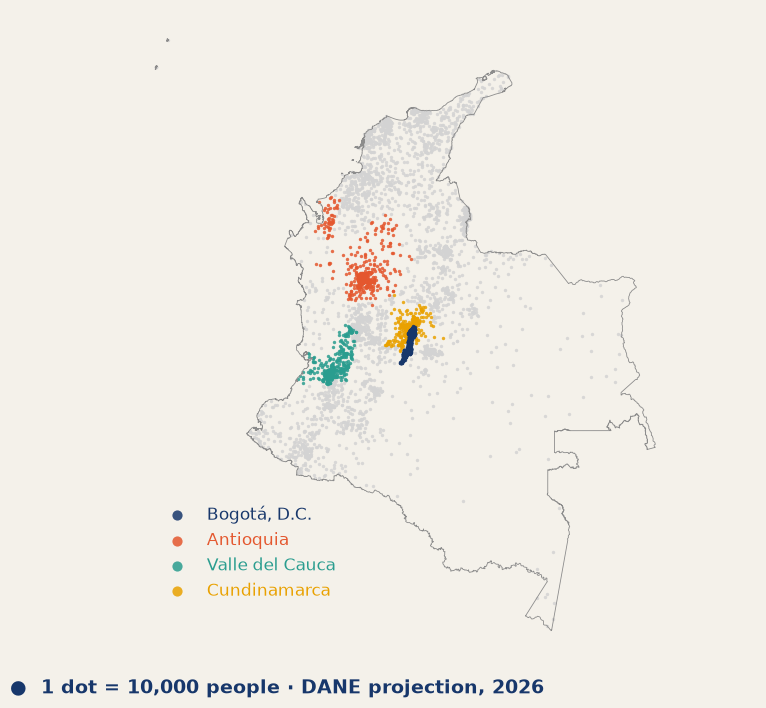

In [6]:
background = "#F4F1EA"
dot_color = "#17376B"
other_color = "#D3D3D3"
palette = ["#17376B", "#E4572E", "#2A9D8F", "#E9A100"]

fig, ax = plt.subplots(figsize=(9.8, 7.0), dpi=100, facecolor=background)
ax.set_facecolor(background)

# Dissolve the municipalities and keep only exterior rings: the shapefile has tiny gaps between
# polygons that would otherwise draw as internal lines
country_parts = list(gdf.union_all().geoms)
outline = geopandas.GeoSeries([part.exterior for part in country_parts], crs=gdf.crs)
outline.plot(ax=ax, color="#8C8C8C", linewidth=0.6)

# Center the view on the mainland, wide enough to still fit the San Andrés islands
mainland_min_x, _, mainland_max_x, _ = max(country_parts, key=lambda part: part.area).bounds
center_x = (mainland_min_x + mainland_max_x) / 2
half_width = center_x - gdf.total_bounds[0] + 0.3
ax.set_xlim(center_x - half_width, center_x + half_width)

dot_style = {"ax": ax, "markersize": 6, "alpha": 0.85, "linewidth": 0}
points[~points["department"].isin(top_departments)].plot(color=other_color, **dot_style)
# Reversed so the top department is drawn last, on top of its neighbours
for department, color in zip(top_departments[::-1], palette[::-1]):
    points[points["department"].eq(department)].plot(
        color=color, label=department.title().replace(" Del ", " del "), **dot_style
    )
ax.set_axis_off()
fig.subplots_adjust(left=0, right=1, top=1, bottom=0.07)

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[::-1], labels[::-1], loc="lower left", bbox_to_anchor=(0, 0.07), frameon=False, fontsize=12,
    labelcolor=palette, markerscale=3,
)

fig.text(
    0.05, 0.03, "●  1 dot = 10,000 people · DANE projection, 2026",
    color=dot_color, fontsize=14, fontweight="bold", va="center",
)

plt.show()